<a href="https://colab.research.google.com/github/allusaatvikacs24-collab/BIS_LAB/blob/main/Lab6%26Lab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

pip install numpy pandas scikit-learn matplotlib

Dataset loaded successfully
Total features: 30
Training samples: 455
Testing samples: 114
Iteration 1/20 | Best Fitness: 0.04819 | Selected Features: 14
Iteration 2/20 | Best Fitness: 0.03864 | Selected Features: 18
Iteration 3/20 | Best Fitness: 0.03964 | Selected Features: 21
Iteration 4/20 | Best Fitness: 0.04431 | Selected Features: 22
Iteration 5/20 | Best Fitness: 0.03999 | Selected Features: 22
Iteration 6/20 | Best Fitness: 0.04717 | Selected Features: 24
Iteration 7/20 | Best Fitness: 0.04648 | Selected Features: 22
Iteration 8/20 | Best Fitness: 0.04116 | Selected Features: 19
Iteration 9/20 | Best Fitness: 0.04867 | Selected Features: 22
Iteration 10/20 | Best Fitness: 0.03147 | Selected Features: 16
Iteration 11/20 | Best Fitness: 0.03615 | Selected Features: 17
Iteration 12/20 | Best Fitness: 0.03324 | Selected Features: 15
Iteration 13/20 | Best Fitness: 0.03943 | Selected Features: 14
Iteration 14/20 | Best Fitness: 0.04014 | Selected Features: 16
Iteration 15/20 | Best 

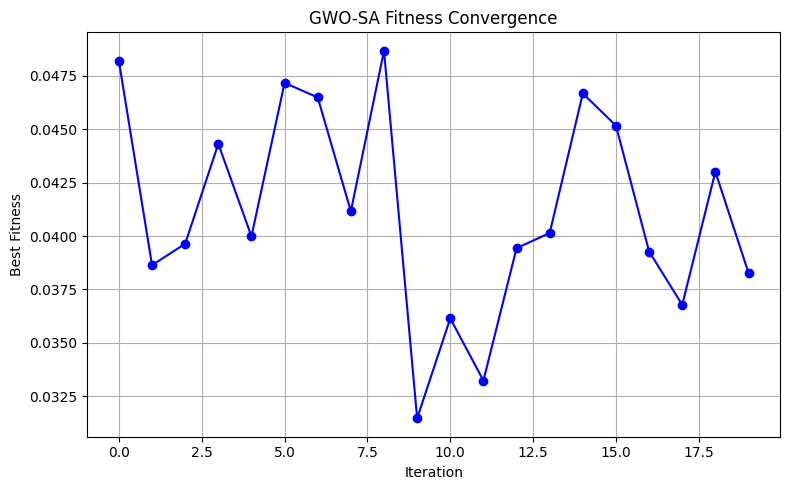

In [2]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ==========================================
# 1. LOAD DATASET
# ==========================================

data = load_breast_cancer()

X = data.data
y = data.target

feature_names = np.array(data.feature_names)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

num_features = X_train.shape[1]

print("Dataset loaded successfully")
print("Total features:", num_features)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# ==========================================
# 2. CLASSIFIER AND FITNESS FUNCTION
# ==========================================

def create_classifier():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ])


def fitness(solution):
    """
    Lower fitness is better.
    Combines classification error and
    number of selected features.
    """

    selected = np.where(solution == 1)[0]

    if len(selected) == 0:
        return 1.0

    model = create_classifier()

    scores = cross_val_score(
        model,
        X_train[:, selected],
        y_train,
        cv=3,
        scoring="accuracy",
        n_jobs=1
    )

    error = 1 - scores.mean()

    # Feature selection penalty
    feature_penalty = len(selected) / num_features

    alpha = 0.99
    beta = 0.01

    return alpha * error + beta * feature_penalty


# ==========================================
# 3. BINARY GREY WOLF OPTIMIZER
# ==========================================

class BinaryGWO:

    def __init__(
        self,
        wolves=10,
        iterations=20,
        sa_temperature=0.1
    ):

        self.wolves = wolves
        self.iterations = iterations
        self.temperature = sa_temperature

        self.population = np.random.randint(
            0, 2,
            (wolves, num_features)
        )

        self.best_solution = None
        self.best_fitness = float("inf")
        self.history = []

    # Binary transfer function
    def sigmoid(self, x):
        return 1 / (1 + np.exp(-np.clip(x, -50, 50)))

    # Evaluate all wolves
    def evaluate_population(self):

        fitness_values = np.array([
            fitness(wolf) for wolf in self.population
        ])

        sorted_indices = np.argsort(fitness_values)

        alpha = self.population[sorted_indices[0]].copy()
        beta = self.population[sorted_indices[1]].copy()
        delta = self.population[sorted_indices[2]].copy()

        return alpha, beta, delta, fitness_values

    # Simulated Annealing local search
    def simulated_annealing(self, solution, current_fitness):

        candidate = solution.copy()

        # Flip one randomly selected feature
        index = np.random.randint(num_features)
        candidate[index] = 1 - candidate[index]

        candidate_fitness = fitness(candidate)

        if candidate_fitness < current_fitness:
            return candidate, candidate_fitness

        # Accept worse solution probabilistically
        probability = np.exp(
            -(candidate_fitness - current_fitness)
            / max(self.temperature, 1e-10)
        )

        if np.random.rand() < probability:
            return candidate, candidate_fitness

        return solution, current_fitness

    # Main optimization function
    def optimize(self):

        for iteration in range(self.iterations):

            # Evaluate wolves
            alpha, beta, delta, fitness_values = (
                self.evaluate_population()
            )

            alpha_fitness = fitness_values[
                np.argmin(fitness_values)
            ]

            if alpha_fitness < self.best_fitness:
                self.best_fitness = alpha_fitness
                self.best_solution = alpha.copy()

            # Linearly decreasing parameter
            a = 2 - 2 * iteration / self.iterations

            new_population = self.population.copy()

            # Update positions
            for i in range(self.wolves):

                X = self.population[i].astype(float)

                candidates = []

                for leader in [alpha, beta, delta]:

                    r1 = np.random.rand(num_features)
                    r2 = np.random.rand(num_features)

                    A = 2 * a * r1 - a
                    C = 2 * r2

                    D = np.abs(C * leader - X)

                    position = leader - A * D

                    candidates.append(position)

                new_position = np.mean(
                    candidates, axis=0
                )

                # Convert continuous position to binary
                probability = self.sigmoid(new_position)

                new_population[i] = (
                    np.random.rand(num_features) < probability
                ).astype(int)

                # Ensure at least one feature is selected
                if np.sum(new_population[i]) == 0:
                    random_index = np.random.randint(num_features)
                    new_population[i][random_index] = 1

            self.population = new_population

            # Linear worst-wolf mutation
            fitness_values = np.array([
                fitness(wolf) for wolf in self.population
            ])

            worst_count = max(
                1,
                int(self.wolves * (iteration + 1)
                    / self.iterations)
            )

            worst_indices = np.argsort(fitness_values)[-worst_count:]

            for index in worst_indices:

                mutated = self.population[index].copy()

                # Move selected bits toward alpha
                for j in range(num_features):
                    if np.random.rand() < 0.1:
                        mutated[j] = alpha[j]

                # Random exploration
                if np.random.rand() < 0.2:
                    j = np.random.randint(num_features)
                    mutated[j] = 1 - mutated[j]

                if np.sum(mutated) > 0:
                    self.population[index] = mutated

            # Simulated annealing on best solution
            self.best_solution, self.best_fitness = (
                self.simulated_annealing(
                    self.best_solution,
                    self.best_fitness
                )
            )

            # Reduce temperature
            self.temperature *= 0.90

            self.history.append(self.best_fitness)

            print(
                f"Iteration {iteration + 1}/{self.iterations} | "
                f"Best Fitness: {self.best_fitness:.5f} | "
                f"Selected Features: "
                f"{np.sum(self.best_solution)}"
            )

        return self.best_solution


# ==========================================
# 4. RUN OPTIMIZATION
# ==========================================

np.random.seed(42)

optimizer = BinaryGWO(
    wolves=10,
    iterations=20,
    sa_temperature=0.1
)

best_features = optimizer.optimize()

selected_indices = np.where(best_features == 1)[0]

print("\nOptimization completed!")

print("Selected feature count:", len(selected_indices))

print("\nSelected Features:")

for index in selected_indices:
    print(feature_names[index])


# ==========================================
# 5. TRAIN RANDOM FOREST
# ==========================================

X_train_selected = X_train[:, selected_indices]
X_test_selected = X_test[:, selected_indices]

model = create_classifier()

model.fit(X_train_selected, y_train)

y_pred = model.predict(X_test_selected)


# ==========================================
# 6. PERFORMANCE EVALUATION
# ==========================================

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

feature_reduction = (
    (num_features - len(selected_indices))
    / num_features
) * 100

print("\n========== FINAL RESULTS ==========")

print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall: {recall * 100:.2f}%")
print(f"F1 Score: {f1 * 100:.2f}%")

print(f"Original Features: {num_features}")
print(f"Selected Features: {len(selected_indices)}")

print(
    f"Feature Reduction: {feature_reduction:.2f}%"
)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


# ==========================================
# 7. FITNESS CONVERGENCE GRAPH
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(
    optimizer.history,
    color="blue",
    marker="o"
)

plt.title("GWO-SA Fitness Convergence")
plt.xlabel("Iteration")
plt.ylabel("Best Fitness")

plt.grid(True)
plt.tight_layout()
plt.show()
#https://researchsystem.canberra.edu.au/ws/portalfiles/portal/52593995/An_Improved_Binary_Grey_Wolf_Optimizer_With_Simulated_Annealing_for_Feature_Selection.pdf

Iteration 1: Temperature = 27.48°C, Humidity = 64.73%
Iteration 2: Temperature = 27.48°C, Humidity = 64.73%
Iteration 3: Temperature = 27.48°C, Humidity = 64.72%
Iteration 4: Temperature = 27.48°C, Humidity = 64.73%
Iteration 5: Temperature = 27.48°C, Humidity = 64.73%
Iteration 6: Temperature = 27.48°C, Humidity = 64.74%
Iteration 7: Temperature = 27.48°C, Humidity = 64.74%
Iteration 8: Temperature = 27.48°C, Humidity = 64.73%
Iteration 9: Temperature = 27.48°C, Humidity = 64.74%
Iteration 10: Temperature = 27.48°C, Humidity = 64.73%
Iteration 11: Temperature = 27.48°C, Humidity = 64.73%
Iteration 12: Temperature = 27.48°C, Humidity = 64.73%
Iteration 13: Temperature = 27.48°C, Humidity = 64.72%
Iteration 14: Temperature = 27.48°C, Humidity = 64.71%
Iteration 15: Temperature = 27.48°C, Humidity = 64.72%
Iteration 16: Temperature = 27.48°C, Humidity = 64.73%
Iteration 17: Temperature = 27.48°C, Humidity = 64.73%
Iteration 18: Temperature = 27.48°C, Humidity = 64.72%
Iteration 19: Tempe

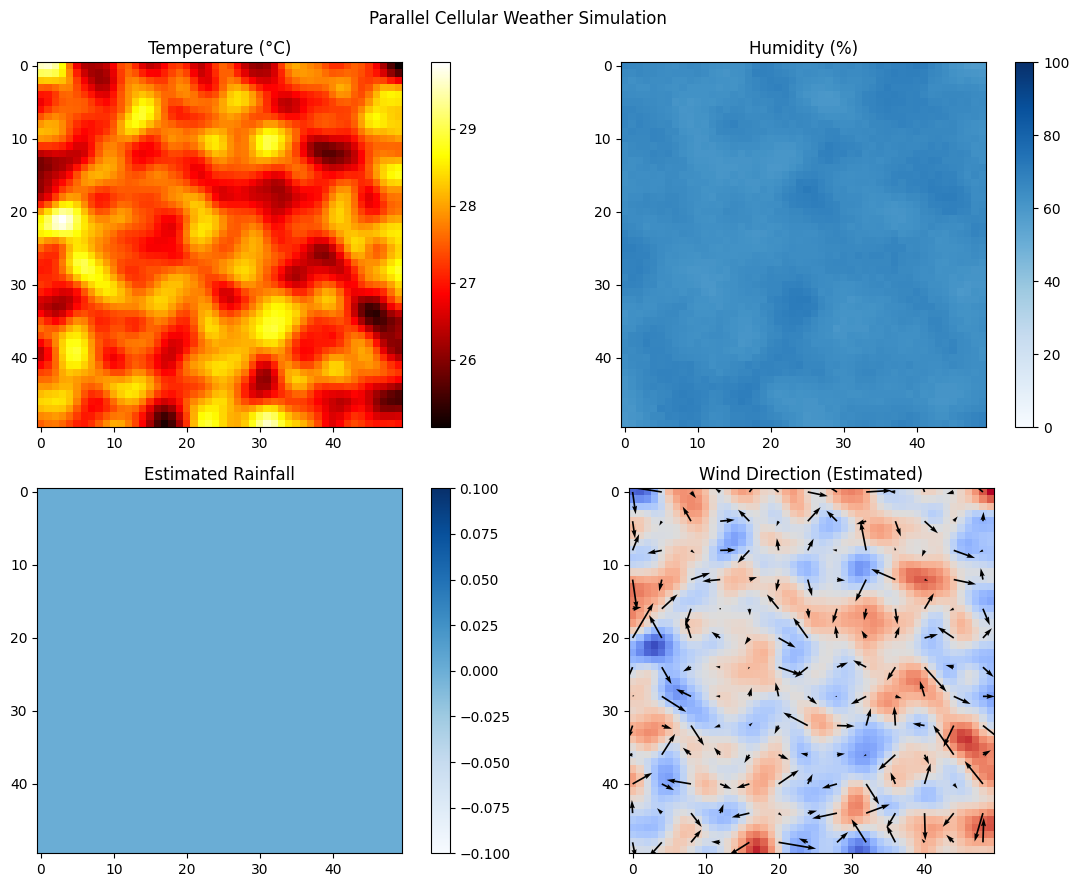


===== WEATHER SIMULATION RESULTS =====
Average Temperature: 27.48 °C
Average Humidity: 64.74 %
Average Rainfall: 0.0
Simulation Completed Successfully!


In [4]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve

# =====================================
# 1. INITIALIZE WEATHER GRID
# =====================================

ROWS = 50
COLS = 50
ITERATIONS = 30

np.random.seed(42)

# Initial temperature (°C)
temperature = np.random.uniform(
    20, 35, (ROWS, COLS)
)

# Initial humidity (%)
humidity = np.random.uniform(
    40, 90, (ROWS, COLS)
)

# Atmospheric pressure (hPa)
pressure = 1013 - 0.2 * temperature

# Neighbor averaging kernel
kernel = np.array([
    [1, 1, 1],
    [1, 0, 1],
    [1, 1, 1]
], dtype=float) / 8


# =====================================
# 2. PARALLEL CELLULAR UPDATE
# =====================================

def update_weather(temp, humid, press):

    # Calculate neighboring temperature
    temp_neighbors = convolve(
        temp, kernel, mode="nearest"
    )

    # Calculate neighboring humidity
    humid_neighbors = convolve(
        humid, kernel, mode="nearest"
    )

    # Update temperature simultaneously
    new_temp = (
        temp + 0.15 * (temp_neighbors - temp)
    )

    # Update humidity simultaneously
    new_humid = (
        humid + 0.20 * (humid_neighbors - humid)
    )

    # Small moisture variation
    new_humid += np.random.normal(
        0, 0.3, (ROWS, COLS)
    )

    new_humid = np.clip(new_humid, 0, 100)

    # Update atmospheric pressure
    new_press = 1013 - 0.2 * new_temp

    # Estimate rainfall
    rainfall = np.where(
        new_humid > 75,
        (new_humid - 75) * 0.5,
        0
    )

    return new_temp, new_humid, new_press, rainfall


# =====================================
# 3. RUN WEATHER SIMULATION
# =====================================

for iteration in range(ITERATIONS):

    temperature, humidity, pressure, rainfall = (
        update_weather(
            temperature,
            humidity,
            pressure
        )
    )

    print(
        f"Iteration {iteration + 1}: "
        f"Temperature = {temperature.mean():.2f}°C, "
        f"Humidity = {humidity.mean():.2f}%"
    )


# =====================================
# 4. CALCULATE WIND DIRECTION
# =====================================

pressure_y, pressure_x = np.gradient(pressure)

wind_x = -pressure_x
wind_y = -pressure_y


# =====================================
# 5. VISUALIZE WEATHER CONDITIONS
# =====================================

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Temperature map
im1 = axes[0, 0].imshow(
    temperature, cmap="hot"
)
axes[0, 0].set_title("Temperature (°C)")
plt.colorbar(im1, ax=axes[0, 0])

# Humidity map
im2 = axes[0, 1].imshow(
    humidity, cmap="Blues",
    vmin=0, vmax=100
)
axes[0, 1].set_title("Humidity (%)")
plt.colorbar(im2, ax=axes[0, 1])

# Rainfall map
im3 = axes[1, 0].imshow(
    rainfall, cmap="Blues"
)
axes[1, 0].set_title("Estimated Rainfall")
plt.colorbar(im3, ax=axes[1, 0])

# Wind direction map
axes[1, 1].imshow(
    pressure, cmap="coolwarm"
)

step = 4

axes[1, 1].quiver(
    np.arange(0, COLS, step),
    np.arange(0, ROWS, step),
    wind_x[::step, ::step],
    wind_y[::step, ::step],
    color="black"
)

axes[1, 1].set_title("Wind Direction (Estimated)")

plt.suptitle("Parallel Cellular Weather Simulation")
plt.tight_layout()
plt.show()


# =====================================
# 6. FINAL RESULTS
# =====================================

print("\n===== WEATHER SIMULATION RESULTS =====")

print("Average Temperature:",
      round(temperature.mean(), 2), "°C")

print("Average Humidity:",
      round(humidity.mean(), 2), "%")

print("Average Rainfall:",
      round(rainfall.mean(), 2))

print("Simulation Completed Successfully!")
#https://agupubs.onlinelibrary.wiley.com/doi/10.1029/2020MS002260